In [3]:
# loading the glm single files

import os.path as op
import os
import nibabel as nib
import numpy as np
from my_utils import get_basic_mask

bids_folder_subjects = '/mnt_AdaBD_largefiles/Data/SMILE_DATA/DNumRisk/ds-dnumrisk/derivatives/glm_stim1.denoise/' #stim 2 includes sub-03
bids_folder_input = f'/mnt_AdaBD_largefiles/Data/SMILE_DATA/DNumRisk/ds-dnumrisk/derivatives/'

stimuli = ['1', '2']
subList = {}
ses = '1'

subList = sorted([f[4:6] for f in os.listdir(bids_folder_subjects) 
                if f.startswith("sub-") and len(f) == 6], key=lambda x: int(x))

import os.path as op
import pandas as pd

home_dir = "/mnt_AdaBD_largefiles/Data/SMILE_Data/DNumRisk/ds-dnumrisk/derivatives/phenotype/"
percep_mem_noise = pd.read_csv(op.join(home_dir, "magjudge_bauer-3_sds_unbiased.csv"))

# Prepare containers
sublist_group0 = {'1': [], '2': []}
sublist_group1 = {'1': [], '2': []}

# Group 0: get list of subjects, format as zero-padded strings
g0_raw = percep_mem_noise.loc[percep_mem_noise['group'] == 0, 'subject'].tolist()
g0_formatted = [f"{int(s):02d}" for s in g0_raw]

# Stimulus 1 -> all group 0 subjects
sublist_group0['1'] = [s for s in g0_formatted if s != '03']

# Stimulus 2 -> exclude subject '03' (example)
sublist_group0['2'] = [s for s in g0_formatted if s != '03']

print("Group 0, stim1:", sublist_group0['1'])
print("Group 0, stim2:", sublist_group0['2'])

# Group 1: same procedure
g1_raw = percep_mem_noise.loc[percep_mem_noise['group'] == 1, 'subject'].tolist()
g1_formatted = [f"{int(s):02d}" for s in g1_raw]

sublist_group1['1'] = g1_formatted
sublist_group1['2'] = g1_formatted  # or apply different exclusion if needed

print("Group 1, stim1:", sublist_group1['1'])
print("Group 1, stim2:", sublist_group1['2'])




Group 0, stim1: ['01', '05', '07', '09', '10', '12', '14', '15', '18', '19', '20', '21', '24', '28', '30', '31', '35', '36', '52', '53', '54', '55', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66']
Group 0, stim2: ['01', '05', '07', '09', '10', '12', '14', '15', '18', '19', '20', '21', '24', '28', '30', '31', '35', '36', '52', '53', '54', '55', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66']
Group 1, stim1: ['02', '04', '06', '08', '11', '13', '16', '17', '22', '23', '25', '26', '27', '29', '32', '33', '34', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '56']
Group 1, stim2: ['02', '04', '06', '08', '11', '13', '16', '17', '22', '23', '25', '26', '27', '29', '32', '33', '34', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '56']


controls kept (32): ['01', '05', '07', '09', '10', '12', '14', '15', '18', '19', '20', '21', '24', '28', '30', '31', '35', '36', '52', '53', '54', '55', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66']
DD kept       (33): ['02', '04', '06', '08', '11', '13', '16', '17', '22', '23', '25', '26', '27', '29', '32', '33', '34', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '56']

n control=32, n DD=33, vertices tested=18715
uncorrected p<.05: 1223 vertices
FDR-BH q<.05:      0 vertices


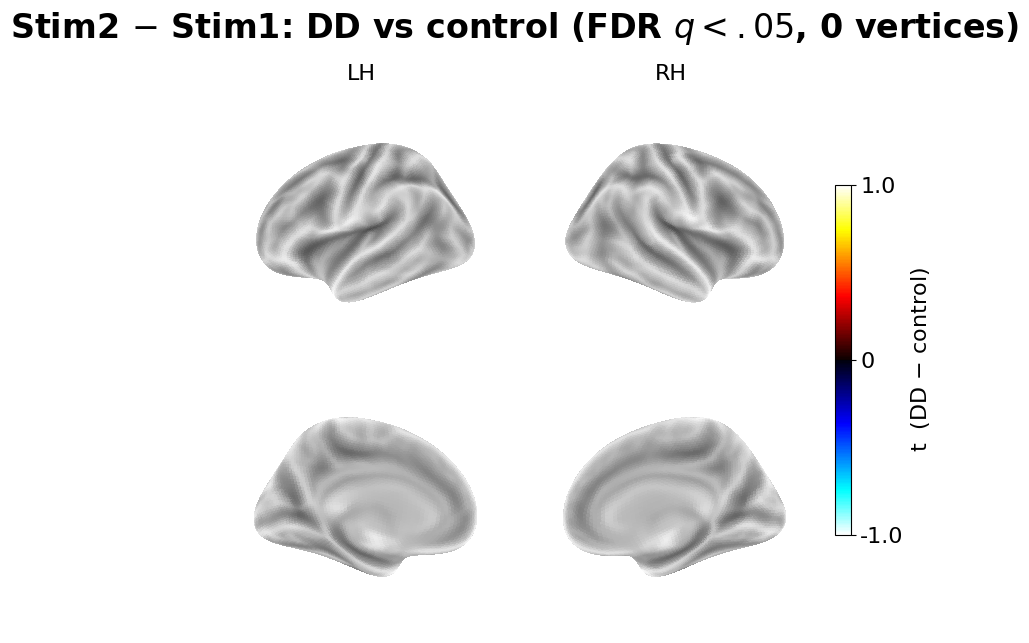

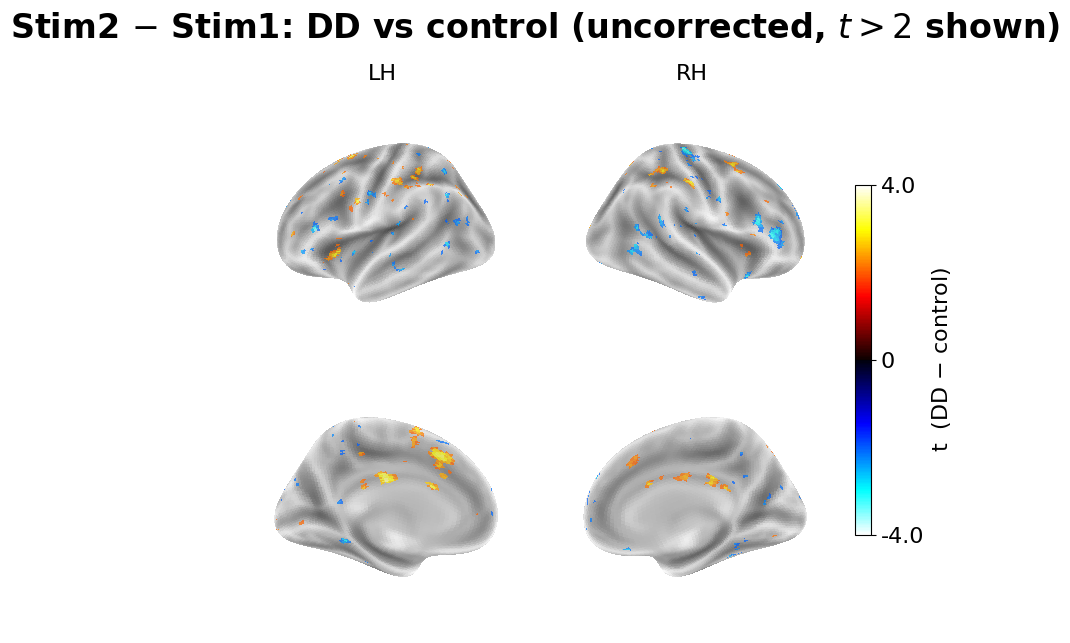

In [4]:
import os.path as op
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import nilearn.plotting as nplt
from nilearn.datasets import fetch_surf_fsaverage
from scipy import stats
from statsmodels.stats.multitest import multipletests
from my_utils import get_basic_mask

# ============================================================
# 0. Settings
# ============================================================
bids_folder_input = '/mnt_AdaBD_largefiles/Data/SMILE_DATA/DNumRisk/ds-dnumrisk/derivatives/'
ses = '1'

mask, labeling_noParcel = get_basic_mask()   # boolean (20484,) for fsaverage5
n_vert = mask.shape[0]

# sublist_group0 / sublist_group1 come from your earlier block:
#   sublist_group0 = {'1': [...controls...], '2': [...controls...]}
#   sublist_group1 = {'1': [...DD...],       '2': [...DD...]}

EQUAL_VAR = True   # set to match your gradient-bin test (Welch -> False)

# ============================================================
# 1. Loaders
# ============================================================
def load_stim_map(sub, stim):
    """Mean activation map over trials, full surface (20484,), or None if a hemi is missing."""
    hemis = []
    for hemi in ['L', 'R']:
        fn = op.join(bids_folder_input, f'glm_stim{stim}.denoise', f'sub-{sub}',
                     f'ses-{ses}', 'func',
                     f'sub-{sub}_ses-1_task-magjudge_space-fsaverage5_stim-{stim}_hemi-{hemi}.func.gii')
        if not op.exists(fn):
            print(f"missing: sub-{sub} stim-{stim} hemi-{hemi}")
            return None
        d = np.asarray(nib.load(fn).agg_data())   # expect (n_vert_hemi, n_trials)
        if d.ndim == 1:
            d = d[:, None]
        hemis.append(d)
    full = np.vstack(hemis)                        # (20484, n_trials)
    return full.mean(axis=1)                       # collapse trials -> activation map

def group_diff(sub_stim1, sub_stim2):
    """Per-subject stim2-stim1 difference maps for subjects present in both stimuli."""
    subs = sorted(set(sub_stim1) & set(sub_stim2), key=lambda x: int(x))
    diffs, kept = [], []
    for sub in subs:
        m1, m2 = load_stim_map(sub, '1'), load_stim_map(sub, '2')
        if m1 is None or m2 is None:
            continue
        diffs.append(m2 - m1)
        kept.append(sub)
    return np.array(diffs), kept                   # (n_subs, 20484)

# ============================================================
# 2. Build per-subject difference maps
# ============================================================
diff_g0, subs_g0 = group_diff(sublist_group0['1'], sublist_group0['2'])  # controls
diff_g1, subs_g1 = group_diff(sublist_group1['1'], sublist_group1['2'])  # DD

print(f"controls kept ({len(subs_g0)}): {subs_g0}")
print(f"DD kept       ({len(subs_g1)}): {subs_g1}")

# ============================================================
# 3. Diff-of-diff: DD vs control on (stim2 - stim1), vertex-wise + FDR
# ============================================================
d0 = diff_g0[:, mask]        # (n_control, n_masked)
d1 = diff_g1[:, mask]        # (n_dd,      n_masked)

t, p = stats.ttest_ind(d1, d0, axis=0, equal_var=EQUAL_VAR)   # +t = DD > control

valid = ~np.isnan(p)
reject = np.zeros_like(p, dtype=bool)
p_fdr  = np.full_like(p, np.nan)
reject[valid], p_fdr[valid], _, _ = multipletests(p[valid], alpha=0.05, method='fdr_bh')

print(f"\nn control={d0.shape[0]}, n DD={d1.shape[0]}, vertices tested={int(mask.sum())}")
print(f"uncorrected p<.05: {(p[valid] < .05).sum()} vertices")
print(f"FDR-BH q<.05:      {reject.sum()} vertices")
if reject.any():
    print(f"min FDR q = {np.nanmin(p_fdr):.4g}")

# re-embed to full surface (L-first, matches np.split downstream)
idx = np.where(mask)[0]
t_full = np.zeros(n_vert); t_full[mask] = np.nan_to_num(t)
t_sig  = np.zeros(n_vert); t_sig[idx[reject]] = t[reject]

# ============================================================
# 4. Plotting
# ============================================================
fsaverage = fetch_surf_fsaverage()   # default mesh = fsaverage5 (20484)
size_axis = 16

def plot_stat_surface(vec, title, threshold, vmax=None, cmap='cold_hot'):
    """vec: full-surface (20484,), L-first. LH/RH x lateral/medial + shared symmetric cbar."""
    if vmax is None:
        active = vec[np.abs(vec) >= threshold]
        vmax = np.nanmax(np.abs(active)) if active.size else 1.0
    vmin = -vmax

    gm_l, gm_r = np.split(vec, 2)
    col_hemi = ['left', 'right']

    fig, axes = plt.subplots(2, 2, figsize=(8, 7), subplot_kw=dict(projection='3d'))
    for col, hemi in enumerate(col_hemi):
        gm   = gm_l if hemi == 'left' else gm_r
        surf = fsaverage[f'infl_{hemi}']
        sulc = fsaverage[f'sulc_{hemi}']
        for row, view in enumerate(['lateral', 'medial']):
            nplt.plot_surf_stat_map(
                surf, gm, hemi=hemi, view=view,
                threshold=threshold, vmax=vmax, cmap=cmap,
                colorbar=False, bg_map=sulc, bg_on_data=True,
                axes=axes[row, col]
            )
        axes[0, col].set_title('LH' if hemi == 'left' else 'RH',
                               fontsize=size_axis, pad=10)

    plt.subplots_adjust(hspace=0.05, wspace=0.05, right=0.88)

    # shared symmetric colorbar
    cbar_ax = fig.add_axes([0.90, 0.25, 0.02, 0.5])
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm); sm.set_array([])
    cbar = plt.colorbar(sm, cax=cbar_ax, orientation='vertical')
    cbar.set_ticks([vmin, 0, vmax])
    cbar.set_ticklabels([f'{vmin:.1f}', '0', f'{vmax:.1f}'])
    cbar.ax.tick_params(labelsize=size_axis)
    cbar.ax.set_ylabel('t  (DD $-$ control)', fontsize=size_axis, rotation=90)

    fig.suptitle(title, fontsize=24, fontweight='bold', y=1.0)
    plt.show()

# FDR-significant only (headline panel)
plot_stat_surface(
    t_sig,
    rf'Stim2 $-$ Stim1: DD vs control (FDR $q<.05$, {reject.sum()} vertices)',
    threshold=1e-6
)

# Uncorrected, for the "before correction" comparison panel
plot_stat_surface(
    t_full,
    r'Stim2 $-$ Stim1: DD vs control (uncorrected, $t>2$ shown)',
    threshold=2.0
)